# Transcript abundance

Quantify condition-associated transcript abundance and ribosome-pool redistribution.


In [1]:
import json
import os
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from monopoly import MonopolyDataset, MonopolyModel
from monopoly import __version__ as monopoly_version
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from scipy.stats import spearmanr

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
MIN_COUNT = 10
MIN_TPM = 1.0
N_CPUS = min(4, os.cpu_count() or 1)
EXPECTED_MONOPOLY_VERSION = '0.1.0'
FRACTIONS = {
    'input': ('Input', 'input'),
    'monosome': ('Monosome', 'mono'),
    'polysome': ('Polysome', 'poly'),
}
FRACTION_LABELS = {
    'input': 'Input RNA',
    'monosome': 'Monosome-associated RNA',
    'polysome': 'Polysome-associated RNA',
}
SHORT_LABELS = {
    'input': 'Input',
    'monosome': 'Monosome',
    'polysome': 'Polysome',
    'redistribution': 'Redistribution',
}
FRACTION_OUTPUTS = {
    'input': 'inputDifferentialTranscriptAbundance.tsv',
    'monosome': 'monosomeDifferentialTranscriptAbundance.tsv',
    'polysome': 'polysomeDifferentialTranscriptAbundance.tsv',
}
GENE_RESULTS = {
    'input': 'inputDifferentialExpression.tsv',
    'monosome': 'monosomeDifferentialAbundance.tsv',
    'polysome': 'polysomeDifferentialAbundance.tsv',
    'redistribution': 'polysomeMonosome.tsv',
}
MODEL_METRICS = (
    'baseMean',
    'log2FoldChange',
    'log2FoldChangeSE',
    'statistic',
    'pValue',
    'adjustedPValue',
)

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the analysis metadata.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok = True)

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()
min_samples = int(metadata['condition'].value_counts().min())

if metadata['condition'].isna().any():
    raise ValueError('Metadata contains an unexpected condition.')
if min_samples < 2:
    raise ValueError('Each condition requires at least two participants.')
if monopoly_version != EXPECTED_MONOPOLY_VERSION:
    raise RuntimeError(
        f'Expected Monopoly {EXPECTED_MONOPOLY_VERSION}, found {monopoly_version}.'
    )

display(metadata)


,familyId,condition
sampleId,,
07c06,1077,Unaffected
07c13,1077,Unaffected
07c16,1077,Unaffected
1851,1077,ASD
1861,1077,ASD
1916,1077,ASD


In [3]:
# Audit Salmon estimates and construct transcript-level lengthScaledTPM counts.


def length_scaled_counts(
    values: pd.DataFrame,
    abundance: pd.DataFrame,
    lengths: pd.DataFrame,
) -> pd.DataFrame:
    mean_length = lengths.mean(axis = 1)
    scaled = abundance.mul(mean_length, axis = 0)
    return scaled.mul(values.sum(axis = 0) / scaled.sum(axis = 0), axis = 1)


raw_counts = {}
counts = {}
tpm = {}
filters = {}
grid_masks = {}
audit_records = []
length_records = []
filter_records = []
annotations = None
gene_names = None

for fraction, (folder, prefix) in FRACTIONS.items():
    count_path = DATA_DIR / folder / 'salmon.merged.transcript_counts.tsv'
    tpm_path = DATA_DIR / folder / 'salmon.merged.transcript_tpm.tsv'
    length_path = DATA_DIR / folder / 'salmon.merged.transcript_lengths.tsv'
    gene_path = DATA_DIR / folder / 'salmon.merged.gene_counts.tsv'
    count_table = pd.read_csv(count_path, sep = '\t')
    tpm_table = pd.read_csv(tpm_path, sep = '\t')
    length_table = pd.read_csv(length_path, sep = '\t')
    gene_table = pd.read_csv(gene_path, sep = '\t')
    columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]
    required = {'tx', 'gene_id', *columns}

    for input_path, table in (
        (count_path, count_table),
        (tpm_path, tpm_table),
        (length_path, length_table),
    ):
        missing = required.difference(table.columns)
        if missing:
            raise ValueError(f'{input_path.name} is missing: {sorted(missing)}')
        if table['tx'].isna().any() or not table['tx'].is_unique:
            raise ValueError(
                f'Transcript identifiers are invalid in {input_path.name}.'
            )
        if table['gene_id'].isna().any():
            raise ValueError(
                f'Parent gene identifiers are incomplete in {input_path.name}.'
            )

    identifiers = count_table[['tx', 'gene_id']]
    if not identifiers.equals(tpm_table[['tx', 'gene_id']]):
        raise ValueError(f'Count and TPM identifiers disagree in {folder}.')
    if not identifiers.equals(length_table[['tx', 'gene_id']]):
        raise ValueError(f'Count and length identifiers disagree in {folder}.')

    if annotations is None:
        annotations = identifiers.rename(
            columns = {'tx': 'transcriptId', 'gene_id': 'parentGeneId'}
        ).set_index('transcriptId')
    elif not annotations[['parentGeneId']].reset_index().rename(columns = {
        'transcriptId': 'tx',
        'parentGeneId': 'gene_id',
    }).equals(identifiers):
        raise ValueError(f'Transcript annotations disagree in {folder}.')

    current_gene_names = gene_table.set_index('gene_id')['gene_name']
    if not current_gene_names.index.is_unique:
        raise ValueError(f'Gene identifiers are duplicated in {gene_path.name}.')
    if gene_names is None:
        gene_names = current_gene_names
    elif not gene_names.equals(current_gene_names):
        raise ValueError(f'Gene annotations disagree in {folder}.')

    count_values = count_table.set_index('tx').loc[:, columns]
    tpm_values = tpm_table.set_index('tx').loc[:, columns]
    length_values = length_table.set_index('tx').loc[:, columns]
    count_values.columns = sample_ids
    tpm_values.columns = sample_ids
    length_values.columns = sample_ids

    for label, values in (
        ('counts', count_values),
        ('TPM', tpm_values),
        ('effective lengths', length_values),
    ):
        array = values.to_numpy(dtype = 'float64')
        if not np.isfinite(array).all() or (array < 0).any():
            raise ValueError(f'{folder} {label} must be finite and nonnegative.')

    transcript_sums = count_values.groupby(
        identifiers['gene_id'].to_numpy(),
        sort = False,
    ).sum()
    gene_values = gene_table.set_index('gene_id').loc[
        transcript_sums.index,
        columns,
    ]
    maximum_sum_error = np.abs(
        transcript_sums.to_numpy() - gene_values.to_numpy()
    ).max()
    if maximum_sum_error > 1e-6:
        raise ValueError(f'Transcript counts do not reproduce {folder} gene counts.')

    scaled_values = length_scaled_counts(
        count_values,
        tpm_values,
        length_values,
    )
    library_sum_error = np.abs(
        scaled_values.sum(axis = 0) - count_values.sum(axis = 0)
    ).max()
    if library_sum_error > 1e-5:
        raise ValueError(f'Length-scaled {folder} counts changed library totals.')

    expressed = count_values.sum(axis = 1).gt(0)
    effective = length_values.loc[expressed].to_numpy(dtype = 'float64')
    effective_cv = effective.std(axis = 1) / effective.mean(axis = 1)
    effective_ratio = effective.max(axis = 1) / effective.min(axis = 1)

    audit_records.append({
        'analysis': fraction,
        'transcripts': len(count_values),
        'parentGenes': identifiers['gene_id'].nunique(),
        'allZeroTranscripts': int(count_values.sum(axis = 1).eq(0).sum()),
        'maximumGeneSumError': maximum_sum_error,
        'maximumLibrarySumError': library_sum_error,
        'minimumTpmSum': tpm_values.sum(axis = 0).min(),
        'maximumTpmSum': tpm_values.sum(axis = 0).max(),
        'countsFromAbundance': 'lengthScaledTPM',
        'inferentialReplicatesAvailable': False,
    })
    length_records.append({
        'analysis': fraction,
        'expressedTranscripts': int(expressed.sum()),
        'medianEffectiveLengthCv': np.median(effective_cv),
        'p95EffectiveLengthCv': np.quantile(effective_cv, 0.95),
        'maximumEffectiveLengthCv': effective_cv.max(),
        'p95EffectiveLengthRatio': np.quantile(effective_ratio, 0.95),
    })

    for count_cutoff in (5, 10, 20):
        for tpm_cutoff in (0.5, 1.0, 2.0):
            support = scaled_values.ge(count_cutoff) & tpm_values.ge(tpm_cutoff)
            keep = support.sum(axis = 1).ge(min_samples)
            grid_masks[(fraction, count_cutoff, tpm_cutoff)] = keep
            filter_records.append({
                'analysis': fraction,
                'minimumCount': count_cutoff,
                'minimumTpm': tpm_cutoff,
                'minimumSamples': min_samples,
                'retainedTranscripts': int(keep.sum()),
            })

    filters[fraction] = grid_masks[(fraction, MIN_COUNT, MIN_TPM)]
    gene_tpm = tpm_values.groupby(
        identifiers['gene_id'].to_numpy(),
        sort = False,
    ).transform('sum')
    gene_proportion = tpm_values.divide(gene_tpm.replace(0, np.nan))
    annotations[f'mean{fraction.title()}Tpm'] = tpm_values.mean(axis = 1)
    annotations[f'mean{fraction.title()}GeneProportion'] = gene_proportion.mean(
        axis = 1
    )
    raw_counts[fraction] = count_values
    counts[fraction] = scaled_values
    tpm[fraction] = tpm_values

annotations['geneName'] = annotations['parentGeneId'].map(gene_names)
annotations['parentTranscriptCount'] = annotations['parentGeneId'].map(
    annotations['parentGeneId'].value_counts()
)

if annotations['geneName'].isna().any():
    raise ValueError('At least one transcript lacks a parent gene name.')

for count_cutoff in (5, 10, 20):
    for tpm_cutoff in (0.5, 1.0, 2.0):
        keep = (
            grid_masks[('monosome', count_cutoff, tpm_cutoff)]
            & grid_masks[('polysome', count_cutoff, tpm_cutoff)]
        )
        filter_records.append({
            'analysis': 'redistribution',
            'minimumCount': count_cutoff,
            'minimumTpm': tpm_cutoff,
            'minimumSamples': min_samples,
            'retainedTranscripts': int(keep.sum()),
        })

filters['redistribution'] = filters['monosome'] & filters['polysome']
union_keep = pd.concat(filters.values(), axis = 1).any(axis = 1)

for fraction in FRACTIONS:
    raw_counts[fraction] = raw_counts[fraction].loc[union_keep]
    counts[fraction] = counts[fraction].loc[union_keep]
    tpm[fraction] = tpm[fraction].loc[union_keep]
    filters[fraction] = filters[fraction].loc[union_keep]

filters['redistribution'] = filters['redistribution'].loc[union_keep]
annotations = annotations.loc[union_keep]
quantification_audit = pd.DataFrame(audit_records)
effective_length_audit = pd.DataFrame(length_records)
filter_sensitivity = pd.DataFrame(filter_records)
filter_summary = pd.DataFrame([
    {
        'analysis': analysis,
        'retainedTranscripts': int(keep.sum()),
        'minimumCount': MIN_COUNT,
        'minimumTpm': MIN_TPM,
        'minimumSamples': min_samples,
    }
    for analysis, keep in filters.items()
])

display(quantification_audit)
display(effective_length_audit)
display(filter_summary)


,analysis,transcripts,parentGenes,allZeroTranscripts,maximumGeneSumError,maximumLibrarySumError,minimumTpmSum,maximumTpmSum,countsFromAbundance,inferentialReplicatesAvailable
0,input,646577,78941,337598,2.328306e-10,1.490116e-08,999999.999885,1.000000e+06,lengthScaledTPM,False
1,monosome,646577,78941,395752,1.047738e-09,1.490116e-08,999999.999880,1.000000e+06,lengthScaledTPM,False
2,polysome,646577,78941,381625,1.164153e-10,0.000000e+00,999999.999924,1.000000e+06,lengthScaledTPM,False


,analysis,expressedTranscripts,medianEffectiveLengthCv,p95EffectiveLengthCv,maximumEffectiveLengthCv,p95EffectiveLengthRatio
0,input,308979,0.002785,0.018563,0.076001,1.050176
1,monosome,250825,0.003033,0.019506,0.078397,1.051029
2,polysome,264952,0.002748,0.017875,0.161288,1.060929


,analysis,retainedTranscripts,minimumCount,minimumTpm,minimumSamples
0,input,47878,10,1.0,3
1,monosome,37990,10,1.0,3
2,polysome,43837,10,1.0,3
3,redistribution,31990,10,1.0,3


In [4]:
# Fit one negative-binomial condition model for each sequenced RNA pool.
# Inferential replicates are unavailable.
# Length-scaled estimates are therefore treated as observed.


def fit_fraction_model(analysis: str):
    selected = filters[analysis]
    model_counts = np.rint(
        counts[analysis].loc[selected].T
    ).astype('int64')
    model_counts.index.name = 'sampleId'
    model_counts.columns.name = 'transcriptId'
    dds = DeseqDataSet(
        counts = model_counts,
        metadata = metadata,
        design = '~condition',
        fit_type = 'parametric',
        size_factors_fit_type = 'ratio',
        refit_cooks = False,
        n_cpus = N_CPUS,
        quiet = True,
    )
    dds.deseq2()

    coefficient = 'condition[T.ASD]'
    if coefficient not in dds.varm['LFC'].columns:
        raise ValueError(f'Expected coefficient not found for {analysis}.')

    statistics = DeseqStats(
        dds,
        contrast = ['condition', TEST, REFERENCE],
        alpha = ALPHA,
        cooks_filter = True,
        independent_filter = True,
        n_cpus = N_CPUS,
        quiet = True,
    )
    with redirect_stdout(StringIO()):
        statistics.summary()

    result = statistics.results_df.rename(columns = {
        'lfcSE': 'log2FoldChangeSE',
        'stat': 'statistic',
        'pvalue': 'pValue',
        'padj': 'adjustedPValue',
    }).copy()
    result.insert(
        0,
        'parentGeneId',
        annotations['parentGeneId'].reindex(result.index),
    )
    result.insert(1, 'geneName', annotations['geneName'].reindex(result.index))
    result['meanTpm'] = annotations[
        f'mean{analysis.title()}Tpm'
    ].reindex(result.index)
    result['meanGeneProportion'] = annotations[
        f'mean{analysis.title()}GeneProportion'
    ].reindex(result.index)
    result['parentTranscriptCount'] = annotations[
        'parentTranscriptCount'
    ].reindex(result.index)
    result['significant'] = result['adjustedPValue'].lt(ALPHA)
    result.index.name = 'transcriptId'
    result = result.sort_values(
        ['adjustedPValue', 'pValue'],
        na_position = 'last',
    )

    summary = {
        'analysis': analysis,
        'retainedTranscripts': len(result),
        'convergedTranscripts': int(
            dds.var['_LFC_converged'].fillna(False).sum()
        ),
        'undefinedPValueTranscripts': int(result['pValue'].isna().sum()),
        'independentlyFilteredTranscripts': int(
            (
                result['pValue'].notna()
                & result['adjustedPValue'].isna()
            ).sum()
        ),
        'significantTranscripts': int(result['significant'].sum()),
    }
    dispersion = pd.DataFrame({
        'baseMean': result['baseMean'],
        'dispersion': dds.var['dispersions'].reindex(result.index),
    })
    size_factors = dds.obs[['size_factors']].rename(
        columns = {'size_factors': 'sizeFactor'}
    )
    size_factors['analysis'] = analysis
    return result, summary, dispersion, size_factors


fraction_results = {}
fraction_summaries = []
dispersion_tables = {}
fraction_size_factors = []


In [5]:
# Model input transcript abundance.

(
    fraction_results['input'],
    input_summary,
    dispersion_tables['input'],
    input_size_factors,
) = fit_fraction_model('input')
fraction_summaries.append(input_summary)
fraction_size_factors.append(input_size_factors)
fraction_results['input'].reset_index().to_csv(
    RESULTS_DIR / FRACTION_OUTPUTS['input'],
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
display(pd.DataFrame([input_summary]))
display(fraction_results['input'].head(15))


,analysis,retainedTranscripts,convergedTranscripts,undefinedPValueTranscripts,independentlyFilteredTranscripts,significantTranscripts
0,input,47878,47878,524,0,614


,parentGeneId,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,meanTpm,meanGeneProportion,parentTranscriptCount,significant
transcriptId,,,,,,,,,,,,
ENST00000457233.6,ENSG00000242086.9,MUC20-OT1,1113.091289,-5.774409,0.412222,-14.008003,1.392658e-44,6.594791e-40,8.615490,0.167162,249,True
ENST00000488803.1,ENSG00000240342.3,RPS2P5,11850.252913,-4.338693,0.328488,-13.208074,7.881531e-40,1.866110e-35,312.948077,1.000000,1,True
ENST00000685247.3,ENSG00000289047.3,ENSG00000289047,1529.080690,-2.001945,0.156207,-12.815959,1.334780e-37,2.106905e-33,7.472604,0.635601,4,True
ENST00000380870.9,ENSG00000172687.16,ZNF738,1524.519222,-1.734401,0.140932,-12.306664,8.339944e-35,9.873243e-31,27.132160,0.388342,26,True
ENST00000561569.6,ENSG00000131143.12,COX4I1,1442.061824,2.953866,0.256048,11.536357,8.651225e-31,8.193402e-27,43.147854,0.055666,57,True
ENST00000909789.2,ENSG00000167863.14,ATP5PD,217.541381,-5.163509,0.455007,-11.348189,7.571444e-30,5.975636e-26,5.354350,0.018327,30,True
ENST00000949408.1,ENSG00000173660.14,UQCRH,457.202392,2.362855,0.215545,10.962244,5.804184e-28,3.926448e-24,23.111190,0.042604,40,True
ENST00000418710.3,ENSG00000164651.19,SP8,3574.013100,1.556058,0.142807,10.896211,1.201579e-27,7.112446e-24,17.836751,0.831755,3,True
ENST00000467317.6,ENSG00000137210.16,TMEM14B,197.253537,7.085758,0.695087,10.194059,2.107755e-24,1.109007e-20,2.989726,0.023523,93,True


In [6]:
# Model monosome-associated transcript abundance.

(
    fraction_results['monosome'],
    monosome_summary,
    dispersion_tables['monosome'],
    monosome_size_factors,
) = fit_fraction_model('monosome')
fraction_summaries.append(monosome_summary)
fraction_size_factors.append(monosome_size_factors)
fraction_results['monosome'].reset_index().to_csv(
    RESULTS_DIR / FRACTION_OUTPUTS['monosome'],
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
display(pd.DataFrame([monosome_summary]))
display(fraction_results['monosome'].head(15))


,analysis,retainedTranscripts,convergedTranscripts,undefinedPValueTranscripts,independentlyFilteredTranscripts,significantTranscripts
0,monosome,37990,37990,736,0,433


,parentGeneId,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,meanTpm,meanGeneProportion,parentTranscriptCount,significant
transcriptId,,,,,,,,,,,,
ENST00000457233.6,ENSG00000242086.9,MUC20-OT1,1975.443390,-6.541054,0.274766,-23.805887,2.902391e-125,1.081257e-120,9.278101,0.201625,249,True
ENST00001061868.1,ENSG00000182774.15,RPS17,2101.428731,-4.618296,0.223467,-20.666533,6.932110e-95,1.291244e-90,35.256978,0.005363,31,True
ENST00000488803.1,ENSG00000240342.3,RPS2P5,20747.605752,-4.570042,0.321026,-14.235755,5.496569e-46,6.825639e-42,340.650880,1.000000,1,True
ENST00000849477.1,ENSG00000259551.2,ENSG00000259551,1117.611702,-4.035509,0.303490,-13.297026,2.408609e-40,2.243258e-36,5.434293,0.152278,19,True
ENST00000320996.15,ENSG00000180957.20,PITPNB,381.646609,2.707326,0.215615,12.556272,3.672301e-36,2.736158e-32,1.580620,0.220109,13,True
ENST00000561569.6,ENSG00000131143.12,COX4I1,1721.743193,3.150970,0.260168,12.111292,9.203285e-34,5.714320e-30,32.330801,0.046600,57,True
ENST00000751255.1,ENSG00000291091.2,ENSG00000291091,447.466812,-4.422084,0.433317,-10.205203,1.879282e-24,1.000154e-20,2.329176,0.132356,88,True
ENST00000443998.1,ENSG00000230202.1,RPL29P4,3368.623192,-3.561388,0.349492,-10.190189,2.193368e-24,1.021397e-20,157.132937,1.000000,1,True
ENST00000637677.2,ENSG00000245870.6,LINC00682,2267.858651,-3.953499,0.410996,-9.619302,6.627919e-22,2.743517e-18,34.497639,0.894443,9,True


In [7]:
# Model polysome-associated transcript abundance.

(
    fraction_results['polysome'],
    polysome_summary,
    dispersion_tables['polysome'],
    polysome_size_factors,
) = fit_fraction_model('polysome')
fraction_summaries.append(polysome_summary)
fraction_size_factors.append(polysome_size_factors)
fraction_results['polysome'].reset_index().to_csv(
    RESULTS_DIR / FRACTION_OUTPUTS['polysome'],
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
display(pd.DataFrame([polysome_summary]))
display(fraction_results['polysome'].head(15))


,analysis,retainedTranscripts,convergedTranscripts,undefinedPValueTranscripts,independentlyFilteredTranscripts,significantTranscripts
0,polysome,43837,43837,1251,0,449


,parentGeneId,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,meanTpm,meanGeneProportion,parentTranscriptCount,significant
transcriptId,,,,,,,,,,,,
ENST00000393655.4,ENSG00000008196.14,TFAP2B,1776.678341,-3.396114,0.223949,-15.164670,6.060291e-52,2.580836e-47,4.633893,0.896322,4,True
ENST00000488803.1,ENSG00000240342.3,RPS2P5,7942.713960,-4.161749,0.374232,-11.120762,9.941880e-29,2.116924e-24,172.654501,1.000000,1,True
ENST00000445193.7,ENSG00000163684.13,RPP14,456.634671,2.073090,0.208416,9.946869,2.602416e-23,3.694216e-19,0.866576,0.124579,14,True
ENST00000751255.1,ENSG00000291091.2,ENSG00000291091,189.166414,-5.360271,0.541866,-9.892241,4.498444e-23,4.789268e-19,1.312477,0.119333,88,True
ENST00000851050.2,ENSG00000173660.14,UQCRH,290.379976,2.952737,0.307732,9.595154,8.379173e-22,7.136710e-18,8.428982,0.013057,40,True
ENST00000226382.4,ENSG00000109132.8,PHOX2B,3921.830564,-3.721553,0.389476,-9.555277,1.232539e-21,8.748154e-18,21.302634,0.954527,3,True
ENST00000380707.9,ENSG00000172062.19,SMN1,3663.993237,-0.896356,0.100554,-8.914181,4.914346e-19,2.989748e-15,42.676407,0.710417,23,True
ENST00000621230.1,ENSG00000276791.1,ENSG00000276791,229.537244,1.759165,0.201650,8.723859,2.688775e-18,1.431302e-14,1.127757,1.000000,1,True
ENST00000561569.6,ENSG00000131143.12,COX4I1,2040.734647,3.058604,0.352994,8.664755,4.524861e-18,2.141064e-14,54.343206,0.045792,57,True


In [8]:
# Verify fraction-model normalization and summarize model fits.

fraction_model_summary = pd.DataFrame(fraction_summaries)
fraction_size_factors = pd.concat(fraction_size_factors).reset_index()

if not np.isfinite(fraction_size_factors['sizeFactor']).all():
    raise ValueError('Fraction-model size factors must be finite.')
if not fraction_size_factors['sizeFactor'].gt(0).all():
    raise ValueError('Fraction-model size factors must be positive.')

display(fraction_model_summary)
display(fraction_size_factors)


,analysis,retainedTranscripts,convergedTranscripts,undefinedPValueTranscripts,independentlyFilteredTranscripts,significantTranscripts
0,input,47878,47878,524,0,614
1,monosome,37990,37990,736,0,433
2,polysome,43837,43837,1251,0,449


,sampleId,sizeFactor,analysis
0,07c06,1.111358,input
1,07c13,0.948837,input
2,07c16,1.019172,input
3,1851,1.028578,input
4,1861,1.019020,input
5,1916,0.995665,input
6,07c06,0.978075,monosome
7,07c13,1.060609,monosome
8,07c16,1.065069,monosome
9,1851,1.123336,monosome


In [9]:
# Fit the participant-paired condition-by-fraction transcript model.

redistribution_keep = filters['redistribution']
redistribution_counts = {
    fraction: np.rint(
        values.loc[redistribution_keep].T
    ).astype('int64')
    for fraction, values in counts.items()
}

for values in redistribution_counts.values():
    values.index.name = 'sampleId'
    values.columns.name = 'transcriptId'

transcript_metadata = annotations.loc[
    redistribution_keep,
    ['geneName'],
]
dataset = MonopolyDataset(
    input = redistribution_counts['input'],
    monosome = redistribution_counts['monosome'],
    polysome = redistribution_counts['polysome'],
    metadata = metadata,
    gene_metadata = transcript_metadata,
)
model = MonopolyModel(
    dataset = dataset,
    reference = REFERENCE,
).fit(
    normalization = 'fraction',
    fit_type = 'parametric',
    size_factor_fit_type = 'ratio',
    n_cpus = N_CPUS,
)
design = model.design_matrix
design_summary = pd.DataFrame({
    'libraries': [design.shape[0]],
    'parameters': [design.shape[1]],
    'rank': [np.linalg.matrix_rank(design.to_numpy())],
    'residualDegreesOfFreedom': [design.shape[0] - design.shape[1]],
})

if design_summary.loc[0, 'rank'] != design.shape[1]:
    raise ValueError('The transcript redistribution design is not full rank.')
if design_summary.loc[0, 'residualDegreesOfFreedom'] <= 0:
    raise ValueError(
        'The transcript redistribution design has no residual degrees of freedom.'
    )

contrast_results = {
    'polysomeMonosome': model.contrast(
        'poly',
        'mono',
        alpha = ALPHA,
        cooks_filter = False,
        independent_filter = True,
    ),
    'polysomeInput': model.contrast(
        'poly',
        'input',
        alpha = ALPHA,
        cooks_filter = False,
        independent_filter = True,
    ),
    'monosomeInput': model.contrast(
        'mono',
        'input',
        alpha = ALPHA,
        cooks_filter = False,
        independent_filter = True,
    ),
}
raw_redistribution = contrast_results['polysomeMonosome'].table.copy()
raw_diagnostics = contrast_results['polysomeMonosome'].diagnostics.copy()
transcript_redistribution = raw_redistribution.rename(
    columns = {'geneId': 'transcriptId'}
)
transcript_redistribution.insert(
    1,
    'parentGeneId',
    transcript_redistribution['transcriptId'].map(
        annotations['parentGeneId']
    ),
)
transcript_redistribution['meanTpm'] = transcript_redistribution[
    'transcriptId'
].map(
    (
        annotations['meanMonosomeTpm']
        + annotations['meanPolysomeTpm']
    ) / 2
)
transcript_redistribution['meanGeneProportion'] = transcript_redistribution[
    'transcriptId'
].map(
    (
        annotations['meanMonosomeGeneProportion']
        + annotations['meanPolysomeGeneProportion']
    ) / 2
)
transcript_redistribution['parentTranscriptCount'] = transcript_redistribution[
    'transcriptId'
].map(annotations['parentTranscriptCount'])
transcript_redistribution['significant'] = transcript_redistribution[
    'adjustedPValue'
].lt(ALPHA)
transcript_redistribution_diagnostics = raw_diagnostics.rename(
    columns = {'geneId': 'transcriptId'}
)

failed_transcripts = int(
    transcript_redistribution_diagnostics['fitStatus'].eq('failed').sum()
)
if failed_transcripts / len(transcript_redistribution_diagnostics) > 0.01:
    raise RuntimeError('More than 1% of transcript redistribution fits failed.')

theta_pm = contrast_results['polysomeMonosome'].table.set_index(
    'geneId'
)['log2FoldChange']
theta_pi = contrast_results['polysomeInput'].table.set_index(
    'geneId'
)['log2FoldChange']
theta_mi = contrast_results['monosomeInput'].table.set_index(
    'geneId'
)['log2FoldChange']
algebra_error = theta_pm - (theta_pi - theta_mi)

if not np.allclose(
    theta_pm,
    theta_pi - theta_mi,
    rtol = 1e-10,
    atol = 1e-10,
    equal_nan = True,
):
    raise ValueError('Transcript redistribution contrasts violate their identity.')

redistribution_summary = pd.DataFrame({
    'retainedTranscripts': [len(transcript_redistribution)],
    'fittedTranscripts': [int(
        transcript_redistribution_diagnostics['fitStatus'].eq('fitted').sum()
    )],
    'failedTranscripts': [failed_transcripts],
    'independentlyFilteredTranscripts': [int(
        transcript_redistribution_diagnostics['independentFilter'].sum()
    )],
    'significantTranscripts': [int(
        transcript_redistribution['significant'].sum()
    )],
    'maximumAlgebraError': [algebra_error.abs().max()],
})
redistribution_size_factors = model.size_factors.reset_index()
redistribution_provenance = {
    'analysisUnit': 'transcript',
    'sourceCounts': (
        'lengthScaledTPM reconstructed from Salmon counts, TPM, and '
        'effective lengths'
    ),
    'inferentialReplicatesAvailable': False,
    'monopoly': contrast_results['polysomeMonosome'].provenance,
}

transcript_redistribution.to_csv(
    RESULTS_DIR / 'transcriptRedistribution.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
transcript_redistribution_diagnostics.to_csv(
    RESULTS_DIR / 'transcriptRedistribution.diagnostics.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
(RESULTS_DIR / 'transcriptRedistribution.provenance.json').write_text(
    json.dumps(redistribution_provenance, indent = 2),
    encoding = 'utf-8',
)

display(design_summary)
display(redistribution_summary)


,libraries,parameters,rank,residualDegreesOfFreedom
0,18,10,10,8


,retainedTranscripts,fittedTranscripts,failedTranscripts,independentlyFilteredTranscripts,significantTranscripts,maximumAlgebraError
0,31990,31990,0,0,153,7.105427e-15


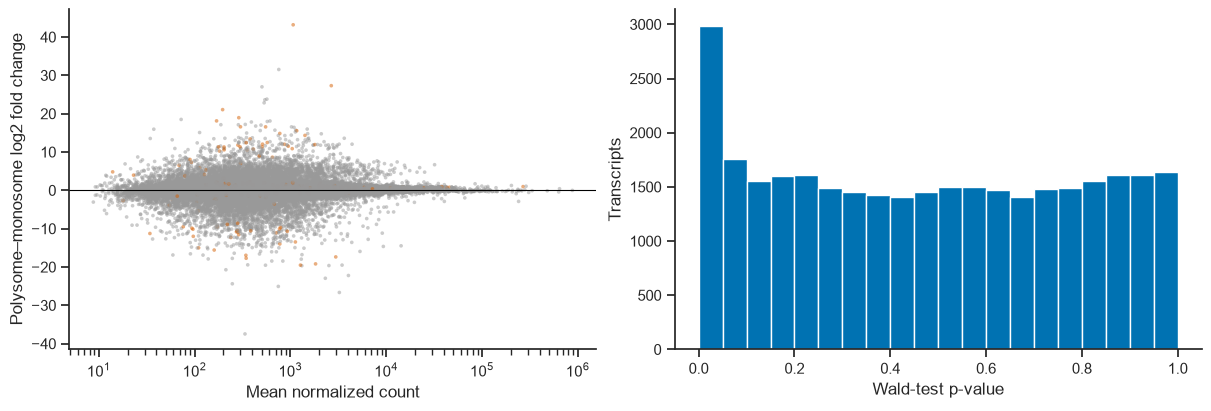

,fraction,minimumSizeFactor,geometricMeanSizeFactor,maximumSizeFactor
0,input,0.927326,1.012298,1.069197
1,monosome,0.918134,1.022966,1.104562
2,polysome,0.928466,1.023081,1.229474


,transcripts,finiteMaxCooks,backendCooksFlags,medianMaxCooks,maximumMaxCooks
0,31990,31990,0,0.439624,717.003485


,transcriptId,parentGeneId,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,meanTpm,meanGeneProportion,parentTranscriptCount,significant
17383,ENST00000539735.6,ENSG00000111652.12,COPS7A,355.262314,1.841115,0.254370,7.237928,4.555902e-13,1.457433e-08,2.696861,0.061420,80,True
8153,ENST00000314744.6,ENSG00000181965.6,NEUROG1,3841.876343,1.403989,0.221512,6.338198,2.324684e-10,3.718332e-06,34.848087,1.000000,1,True
16336,ENST00000309328.8,ENSG00000173465.10,ZNRD2,868.597688,12.009983,1.960794,6.125060,9.064932e-10,9.666239e-06,22.304516,0.379645,26,True
23508,ENST00000573542.6,ENSG00000132507.20,EIF5A,131.197648,5.297065,0.873462,6.064445,1.324103e-09,1.058952e-05,1.872027,0.003267,52,True
25253,ENST00000350690.10,ENSG00000183048.14,SLC25A10,1326.076852,1.105857,0.187468,5.898914,3.659024e-09,2.266241e-05,10.475826,0.880796,41,True
21263,ENST00000859803.2,ENSG00000041357.18,PSMA4,1804.431396,11.933385,2.031513,5.874136,4.250531e-09,2.266241e-05,39.027113,0.166758,46,True
15007,ENST00000934667.1,ENSG00000119953.16,SMNDC1,573.295356,12.468185,2.193293,5.684688,1.310520e-08,5.989078e-05,2.647323,0.154518,26,True
22040,ENST00000312499.6,ENSG00000175643.11,RMI2,2190.697863,1.065445,0.188671,5.647109,1.631681e-08,6.524684e-05,26.706274,0.936765,8,True
26587,ENST00000931989.2,ENSG00000130818.14,ZNF426,379.741068,13.388802,2.431507,5.506381,3.662849e-08,1.301939e-04,1.004635,0.331905,24,True
5632,ENST00000266025.4,ENSG00000126062.6,TMEM115,4645.522764,0.545424,0.101574,5.369707,7.886449e-08,2.522875e-04,31.471866,0.972408,4,True


In [10]:
# Review transcript redistribution normalization, influence, and effect estimates.

normalization_summary = redistribution_size_factors.groupby(
    'fraction',
    observed = True,
)['sizeFactor'].agg(
    minimumSizeFactor = 'min',
    geometricMeanSizeFactor = lambda x: np.exp(np.log(x).mean()),
    maximumSizeFactor = 'max',
).reset_index()
influence = transcript_redistribution_diagnostics.sort_values(
    'maxCooks',
    ascending = False,
)
influence_summary = pd.DataFrame({
    'transcripts': [len(influence)],
    'finiteMaxCooks': [int(np.isfinite(influence['maxCooks']).sum())],
    'backendCooksFlags': [int(influence['cooksOutlier'].sum())],
    'medianMaxCooks': [influence['maxCooks'].median()],
    'maximumMaxCooks': [influence['maxCooks'].max()],
})

if not np.isfinite(redistribution_size_factors['sizeFactor']).all():
    raise ValueError('Transcript redistribution size factors must be finite.')
if not redistribution_size_factors['sizeFactor'].gt(0).all():
    raise ValueError('Transcript redistribution size factors must be positive.')

figure, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)
colors = np.where(
    transcript_redistribution['significant'],
    '#D55E00',
    '#999999',
)
axes[0].scatter(
    transcript_redistribution['baseMean'],
    transcript_redistribution['log2FoldChange'],
    c = colors,
    s = 7,
    alpha = 0.5,
    linewidths = 0,
    rasterized = True,
)
axes[0].axhline(0, color = 'black', linewidth = 0.8)
axes[0].set(
    xscale = 'log',
    xlabel = 'Mean normalized count',
    ylabel = 'Polysome–monosome log2 fold change',
)
axes[1].hist(
    transcript_redistribution['pValue'].dropna(),
    bins = np.linspace(0, 1, 21),
    color = '#0072B2',
    edgecolor = 'white',
)
axes[1].set(xlabel = 'Wald-test p-value', ylabel = 'Transcripts')
sns.despine()
plt.show()

display(normalization_summary)
display(influence_summary)
display(
    transcript_redistribution.sort_values(
        ['adjustedPValue', 'pValue'],
        na_position = 'last',
    ).head(20)
)


In [11]:
# Integrate transcript results and retain missing tests as unavailable.

analysis_results = {
    **fraction_results,
    'redistribution': transcript_redistribution.set_index('transcriptId'),
}
transcript_index = pd.Index(
    sorted(set().union(*(table.index for table in analysis_results.values()))),
    name = 'transcriptId',
)
integrated = annotations.loc[
    transcript_index,
    ['parentGeneId', 'geneName', 'parentTranscriptCount'],
].copy()

for analysis, table in analysis_results.items():
    for metric in (*MODEL_METRICS, 'meanTpm', 'meanGeneProportion'):
        column = f'{analysis}{metric[0].upper()}{metric[1:]}'
        integrated[column] = table[metric].reindex(transcript_index)
    integrated[f'{analysis}Fdr'] = integrated[
        f'{analysis}AdjustedPValue'
    ].lt(ALPHA)

condition_samples = {
    condition: metadata.index[metadata['condition'].eq(condition)].tolist()
    for condition in (REFERENCE, TEST)
}

for analysis in FRACTIONS:
    for condition, participants in condition_samples.items():
        label = condition[0].upper() + condition[1:]
        integrated[f'{analysis}{label}AllZero'] = raw_counts[analysis].loc[
            transcript_index,
            participants,
        ].sum(axis = 1).eq(0)
    integrated[f'{analysis}StructuralZero'] = (
        integrated[f'{analysis}{REFERENCE}AllZero']
        | integrated[f'{analysis}{TEST}AllZero']
    )

integrated['redistributionStructuralZero'] = (
    integrated['monosomeStructuralZero']
    | integrated['polysomeStructuralZero']
)

for analysis in analysis_results:
    integrated[f'{analysis}ExtremeEffect'] = integrated[
        f'{analysis}Log2FoldChange'
    ].abs().gt(5)

gene_results = {
    analysis: pd.read_csv(RESULTS_DIR / filename, sep = '\t').set_index('geneId')
    for analysis, filename in GENE_RESULTS.items()
}

for analysis, table in gene_results.items():
    integrated[f'{analysis}ParentGeneLog2FoldChange'] = integrated[
        'parentGeneId'
    ].map(table['log2FoldChange'])
    integrated[f'{analysis}ParentGeneAdjustedPValue'] = integrated[
        'parentGeneId'
    ].map(table['adjustedPValue'])
    integrated[f'{analysis}ParentGeneFdr'] = integrated[
        f'{analysis}ParentGeneAdjustedPValue'
    ].lt(ALPHA)
    integrated[f'{analysis}ParentGeneNotFdr'] = (
        integrated[f'{analysis}Fdr']
        & ~integrated[f'{analysis}ParentGeneFdr']
    )

fdr_columns = [f'{analysis}Fdr' for analysis in analysis_results]
integrated['fdrLayerCount'] = integrated[fdr_columns].sum(axis = 1)
integrated['fdrLayers'] = integrated[fdr_columns].apply(
    lambda row: ';'.join(
        analysis
        for analysis, column in zip(analysis_results, fdr_columns)
        if row[column]
    ),
    axis = 1,
)

common_transcripts = pd.Index(
    sorted(set.intersection(*(
        set(table.index) for table in analysis_results.values()
    ))),
    name = 'transcriptId',
)
fdr_matrix = integrated.loc[common_transcripts, fdr_columns].copy()
fdr_matrix.columns = list(analysis_results)
selected = fdr_matrix.loc[fdr_matrix.any(axis = 1)]
fdr_overlap = selected.value_counts().rename('transcripts').reset_index()
fdr_overlap['universeTranscripts'] = len(common_transcripts)
fdr_overlap['signature'] = fdr_overlap.apply(
    lambda row: ' + '.join(
        SHORT_LABELS[analysis]
        for analysis in analysis_results
        if row[analysis]
    ),
    axis = 1,
)
fdr_overlap = fdr_overlap.sort_values(
    ['transcripts', 'signature'],
    ascending = [False, True],
)

integrated.reset_index().to_csv(
    RESULTS_DIR / 'transcriptAbundanceComparison.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
fdr_overlap.to_csv(
    RESULTS_DIR / 'transcriptFdrOverlap.tsv',
    sep = '\t',
    index = False,
)

display(fdr_overlap)


,input,monosome,polysome,redistribution,transcripts,universeTranscripts,signature
0,True,False,False,False,222,26206,Input
2,False,True,False,False,139,26206,Monosome
1,False,False,True,False,139,26206,Polysome
3,False,False,False,True,82,26206,Redistribution
4,True,True,True,False,47,26206,Input + Monosome + Polysome
5,True,True,False,False,29,26206,Input + Monosome
6,False,True,False,True,25,26206,Monosome + Redistribution
7,True,False,True,False,23,26206,Input + Polysome
8,False,False,True,True,12,26206,Polysome + Redistribution
9,False,True,True,False,9,26206,Monosome + Polysome


In [12]:
# Audit cross-layer agreement, parent-gene support, and transcript ambiguity.

correlation_records = []
parent_records = []

for x_analysis in analysis_results:
    for y_analysis in analysis_results:
        complete = integrated[[
            f'{x_analysis}Statistic',
            f'{y_analysis}Statistic',
        ]].dropna()
        correlation = spearmanr(complete.iloc[:, 0], complete.iloc[:, 1])
        correlation_records.append({
            'xAnalysis': x_analysis,
            'yAnalysis': y_analysis,
            'transcripts': len(complete),
            'spearmanRho': correlation.statistic,
            'pValue': correlation.pvalue,
        })

for analysis in analysis_results:
    complete = integrated[[
        f'{analysis}Log2FoldChange',
        f'{analysis}ParentGeneLog2FoldChange',
    ]].dropna()
    correlation = spearmanr(complete.iloc[:, 0], complete.iloc[:, 1])
    parent_records.append({
        'analysis': analysis,
        'transcripts': len(complete),
        'spearmanRho': correlation.statistic,
        'pValue': correlation.pvalue,
    })

layer_correlation = pd.DataFrame(correlation_records)
parent_gene_correlation = pd.DataFrame(parent_records)
correlation_matrix = layer_correlation.pivot(
    index = 'yAnalysis',
    columns = 'xAnalysis',
    values = 'spearmanRho',
).reindex(index = analysis_results, columns = analysis_results)

if not np.allclose(correlation_matrix, correlation_matrix.T):
    raise ValueError('Transcript layer correlations are not symmetric.')

candidate_audit = integrated.loc[integrated['fdrLayerCount'].gt(0)].copy()
candidate_audit['minimumFdrLayerMeanGeneProportion'] = np.nan

for transcript_id, row in candidate_audit.iterrows():
    proportions = [
        row[f'{analysis}MeanGeneProportion']
        for analysis in analysis_results
        if row[f'{analysis}Fdr']
    ]
    candidate_audit.loc[
        transcript_id,
        'minimumFdrLayerMeanGeneProportion',
    ] = np.nanmin(proportions)

candidate_audit['lowGeneProportion'] = candidate_audit[
    'minimumFdrLayerMeanGeneProportion'
].lt(0.1)

for analysis in analysis_results:
    significant = candidate_audit.loc[candidate_audit[f'{analysis}Fdr']]
    signs = significant.groupby('parentGeneId')[
        f'{analysis}Log2FoldChange'
    ].agg(['min', 'max'])
    opposing_genes = signs.index[signs['min'].lt(0) & signs['max'].gt(0)]
    candidate_audit[f'{analysis}OpposingTranscriptEffects'] = (
        candidate_audit[f'{analysis}Fdr']
        & candidate_audit['parentGeneId'].isin(opposing_genes)
    )

summary_records = []

for analysis in analysis_results:
    fdr = integrated[f'{analysis}Fdr']
    parent_fdr = integrated[f'{analysis}ParentGeneFdr']
    summary_records.append({
        'analysis': analysis,
        'testedTranscripts': int(
            integrated[f'{analysis}Statistic'].notna().sum()
        ),
        'fdrTranscripts': int(fdr.sum()),
        'fdrParentGenes': int(integrated.loc[fdr, 'parentGeneId'].nunique()),
        'fdrTranscriptsWithParentGeneFdr': int((fdr & parent_fdr).sum()),
        'fdrTranscriptsWithoutParentGeneFdr': int((fdr & ~parent_fdr).sum()),
        'fdrLowGeneProportionTranscripts': int(
            (fdr & candidate_audit['lowGeneProportion'].reindex(
                integrated.index,
                fill_value = False,
            )).sum()
        ),
        'fdrStructuralZeroTranscripts': int(
            (fdr & integrated[f'{analysis}StructuralZero']).sum()
        ),
        'fdrExtremeEffectTranscripts': int(
            (fdr & integrated[f'{analysis}ExtremeEffect']).sum()
        ),
        'fdrOpposingEffectTranscripts': int(
            candidate_audit[f'{analysis}OpposingTranscriptEffects'].sum()
        ),
    })

transcript_summary = pd.DataFrame(summary_records)
layer_correlation.to_csv(
    RESULTS_DIR / 'transcriptLayerCorrelation.tsv',
    sep = '\t',
    index = False,
)
parent_gene_correlation.to_csv(
    RESULTS_DIR / 'transcriptParentGeneCorrelation.tsv',
    sep = '\t',
    index = False,
)
candidate_audit.reset_index().to_csv(
    RESULTS_DIR / 'transcriptCandidateAudit.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
transcript_summary.to_csv(
    RESULTS_DIR / 'transcriptAbundanceSummary.tsv',
    sep = '\t',
    index = False,
)

display(transcript_summary)
display(parent_gene_correlation)


,analysis,testedTranscripts,fdrTranscripts,fdrParentGenes,fdrTranscriptsWithParentGeneFdr,fdrTranscriptsWithoutParentGeneFdr,fdrLowGeneProportionTranscripts,fdrStructuralZeroTranscripts,fdrExtremeEffectTranscripts,fdrOpposingEffectTranscripts
0,input,47878,614,536,132,482,276,197,222,56
1,monosome,37990,433,394,84,349,225,203,218,30
2,polysome,43837,449,420,67,382,228,177,207,17
3,redistribution,31990,153,152,6,147,73,34,64,2


,analysis,transcripts,spearmanRho,pValue
0,input,47878,0.457285,0.0
1,monosome,37990,0.510440,0.0
2,polysome,43837,0.380940,0.0
3,redistribution,31990,0.331761,0.0


In [13]:
# Save complete preprocessing and model diagnostics.

quantification_audit.to_csv(
    RESULTS_DIR / 'transcriptQuantificationAudit.tsv',
    sep = '\t',
    index = False,
)
effective_length_audit.to_csv(
    RESULTS_DIR / 'transcriptEffectiveLengthAudit.tsv',
    sep = '\t',
    index = False,
)
filter_summary.to_csv(
    RESULTS_DIR / 'transcriptFilterSummary.tsv',
    sep = '\t',
    index = False,
)
filter_sensitivity.to_csv(
    RESULTS_DIR / 'transcriptFilterSensitivity.tsv',
    sep = '\t',
    index = False,
)
fraction_model_summary.to_csv(
    RESULTS_DIR / 'transcriptFractionModelSummary.tsv',
    sep = '\t',
    index = False,
)
fraction_size_factors.to_csv(
    RESULTS_DIR / 'transcriptFractionSizeFactors.tsv',
    sep = '\t',
    index = False,
)
redistribution_summary.to_csv(
    RESULTS_DIR / 'transcriptRedistributionSummary.tsv',
    sep = '\t',
    index = False,
)
redistribution_size_factors.to_csv(
    RESULTS_DIR / 'transcriptRedistributionSizeFactors.tsv',
    sep = '\t',
    index = False,
)
